In [20]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def find_project_dir() -> Path:
    """Find the project root from either a notebook or the repository root."""
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd() / "cafe-revenue-regression"]
    for candidate in candidates:
        if (candidate / "data" / "raw" / "train.csv").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy file train.csv trong thư mục data/raw của dự án.")


PROJECT_DIR = find_project_dir()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.data.load import load_raw_data

datasets = load_raw_data(PROJECT_DIR / "data" / "raw")
train = datasets["train"].copy()
stores = datasets["stores"].copy()
weather = datasets["weather"].copy()
holidays = datasets["holidays"].copy()

print(f"Project: {PROJECT_DIR}")
for name, frame in datasets.items():
    print(f"{name:12s}: {frame.shape}")


train        -> Shape: (26632, 4)
stores       -> Shape: (45, 8)
weather      -> Shape: (1593, 4)
holidays     -> Shape: (55, 3)
sample_sub   -> Shape: (3869, 2)
Project: d:\GitHub\ML-Kaggle-Project\cafe-revenue-regression
train       : (26632, 4)
stores      : (45, 8)
weather     : (1593, 4)
holidays    : (55, 3)
sample_sub  : (3869, 2)


In [14]:
schema_report = pd.concat(
    {
        name: frame.dtypes.astype("string")
        for name, frame in datasets.items()
    }, axis=1
).fillna("-")

display(schema_report)

for name, frame in datasets.items():
    date_cols = [col for col in frame.columns if col == "date" or col == "open_date"]
    if date_cols:
        ranges = {
            col: (frame[col].min(), frame[col].max(), int(frame[col].isna().sum()))
            for col in date_cols
        }
        print(name, ranges)


,train,stores,weather,holidays,sample_sub
date,datetime64[us],-,datetime64[us],datetime64[us],-
store_id,category,category,-,-,-
is_promo,int64,-,-,-,-
revenue,float32,-,-,-,float64
city,-,string,string,-,-
district,-,str,-,-,-
store_type,-,str,-,-,-
area_m2,-,float64,-,-,-
seats,-,int64,-,-,-
has_parking,-,int64,-,-,-


train {'date': (Timestamp('2024-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'), 0)}
stores {'open_date': ('06/01/2020', '31/12/2018', 0)}
weather {'date': (Timestamp('2024-01-01 00:00:00'), Timestamp('2026-03-31 00:00:00'), 0)}
holidays {'date': (Timestamp('2024-01-01 00:00:00'), Timestamp('2026-03-08 00:00:00'), 0)}


In [15]:
quality_overview = []
for name, frame in datasets.items():
    quality_overview.append({
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
    })

quality_overview = pd.DataFrame(quality_overview)
display(quality_overview)

revenue_stats = train["revenue"].describe(percentiles=[.5, .9, .95, .99, .999]).to_frame("revenue")
display(revenue_stats)


,dataset,rows,columns,missing_cells,duplicate_rows
0,train,26632,4,0,132
1,stores,45,8,2,0
2,weather,1593,4,16,0
3,holidays,55,3,0,0
4,sample_sub,3869,2,0,0


,revenue
count,26632.000000
mean,51.343407
std,1015.877136
min,0.570000
50%,18.280001
90%,30.450001
95%,34.594499
99%,44.806901
99.9%,12434.390000
max,53600.000000


In [16]:
store_lookup = stores.drop_duplicates("store_id").copy()
weather_lookup = weather.drop_duplicates(["date", "city"]).copy()
holiday_by_date = (
    holidays.dropna(subset=["date"])
    .groupby("date", as_index=False)
    .agg(is_holiday=("holiday_name", "size"), holiday_names=("holiday_name", lambda s: " | ".join(s.astype(str).unique())))
)

eda = train.merge(store_lookup, on="store_id", how="left", validate="many_to_one")
eda = eda.merge(weather_lookup, on=["date", "city"], how="left", validate="many_to_one")
eda = eda.merge(holiday_by_date, on="date", how="left", validate="many_to_one")
eda["is_holiday"] = eda["is_holiday"].fillna(0).gt(0).astype("int8")

print(f"Số dòng train: {len(train):,}; sau ghép: {len(eda):,}")
print("Thiếu sau ghép:")
display(eda[["city", "temp_c", "rain_mm", "is_holiday"]].isna().sum().to_frame("missing"))

daily_revenue = eda.groupby("date", as_index=False).agg(
    revenue=("revenue", "sum"),
    mean_revenue=("revenue", "mean"),
    promo_rate=("is_promo", "mean"),
    is_holiday=("is_holiday", "max"),
    temp_c=("temp_c", "mean"),
    rain_mm=("rain_mm", "mean"),
)
display(daily_revenue.head())


Số dòng train: 26,632; sau ghép: 26,632
Thiếu sau ghép:


,missing
city,0
temp_c,878
rain_mm,1122
is_holiday,0


,date,revenue,mean_revenue,promo_rate,is_holiday,temp_c,rain_mm
0,2024-01-01,500.660004,14.725294,0.000000,1,20.605882,0.000000
1,2024-01-02,526.679993,15.490588,0.000000,0,22.111765,14.447059
2,2024-01-03,561.159973,16.504705,0.000000,0,20.611765,1.835294
3,2024-01-04,616.020020,18.118237,0.029412,0,23.905882,0.000000
4,2024-01-05,584.419983,18.263124,0.031250,0,19.643750,0.000000


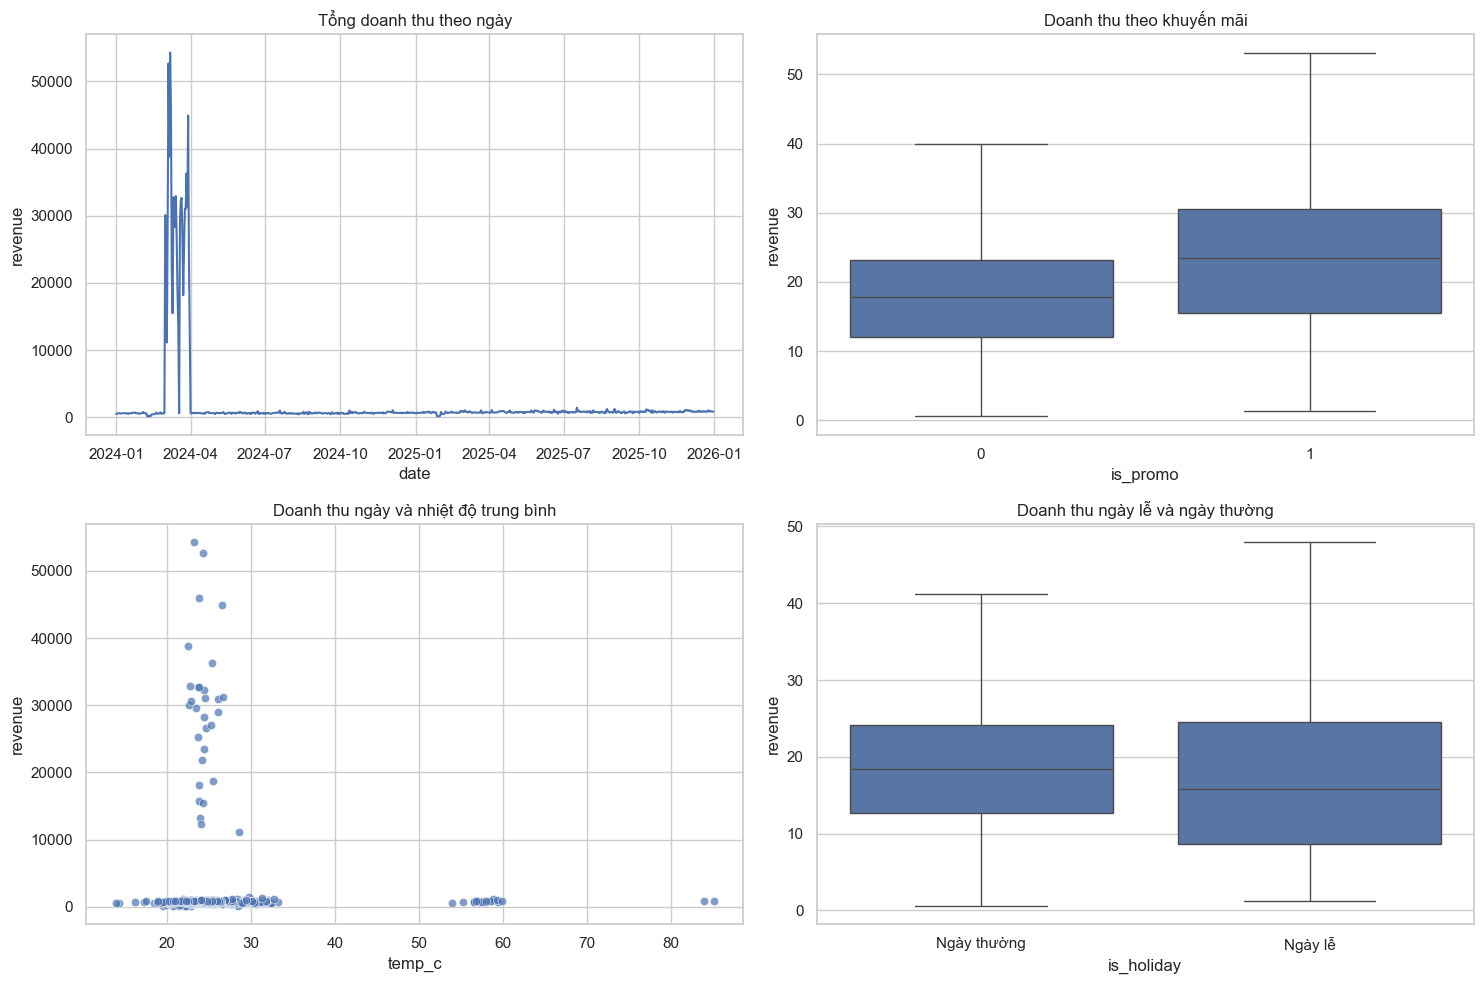

,count,mean,median,std
is_promo,,,,
0,23583,44.029999,17.85,842.539978
1,3049,107.910004,23.48,1876.430054


In [17]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.lineplot(data=daily_revenue, x="date", y="revenue", ax=axes[0, 0], errorbar=None)
axes[0, 0].set_title("Tổng doanh thu theo ngày")

sns.boxplot(data=eda, x="is_promo", y="revenue", showfliers=False, ax=axes[0, 1])
axes[0, 1].set_title("Doanh thu theo khuyến mãi")

sns.scatterplot(data=daily_revenue, x="temp_c", y="revenue", alpha=.7, ax=axes[1, 0])
axes[1, 0].set_title("Doanh thu ngày và nhiệt độ trung bình")

sns.boxplot(data=eda, x="is_holiday", y="revenue", showfliers=False, ax=axes[1, 1])
axes[1, 1].set_xticks([0, 1], ["Ngày thường", "Ngày lễ"])
axes[1, 1].set_title("Doanh thu ngày lễ và ngày thường")

plt.tight_layout()
plt.show()

comparison = eda.groupby("is_promo")["revenue"].agg(["count", "mean", "median", "std"]).round(2)
display(comparison)


In [19]:
q1, q3 = train["revenue"].quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = train["revenue"].lt(lower) | train["revenue"].gt(upper)


print(f"Người dùng IQR: [{lower:.2f}, {upper:.2f}]")
print(f"Ngoài lề: {int(outlier_mask.sum()):,} ({outlier_mask.mean():.2%})")
display(train.loc[outlier_mask].sort_values("revenue", ascending=False).head(20))


Người dùng IQR: [-5.12, 41.68]
Ngoài lề: 422 (1.58%)


,date,store_id,is_promo,revenue
2139,2024-03-07,S12,1,53600.0
2071,2024-03-05,S12,1,51990.0
2173,2024-03-08,S12,1,45130.0
2880,2024-03-29,S12,1,44280.0
2105,2024-03-06,S12,0,38120.0
2813,2024-03-27,S12,0,35780.0
2373,2024-03-14,S12,0,32380.0
2273,2024-03-11,S12,0,32190.0
2610,2024-03-21,S12,0,32110.0
2579,2024-03-20,S12,0,31670.0
